# P1: Factors Affecting Final Grades (student-mat)

**Main question:** How do studytime, absences, family support and intermediate grades (G1/G2) relate to the final grade (G3)?

- Data: UCI Student Performance (`student-mat.csv` primary, `student-por.csv` for comparison) + Wikipedia PISA reference
- Pipeline: `StudentDataProcessor.load_data → clean_data → analyze → export_results` (`data_processor.py`, run via `main.py`)
- Outputs: `data/processed/cleaned_students.csv` (1044 rows), `cleaned_students_mat.csv` (395 rows), `cleaned_students_por.csv` (649 rows), `pisa_clean.csv`, `summary.json`, and charts in `images/`
- Side effects: running the notebook rewrites the same files as `main.py` (`data/processed/*`, `images/*.png`). No network call when the raw files and PISA cache already exist.

## 1. Python basics: 4 functions + data structures

`convert_yes_no`, `calc_pass_fail`, `classify_absences`, `calc_average_grade`; `list[dict]` sample students, `dict` mapping, `set()` uniques, `tuple` thresholds.

In [1]:
from data_processor import (
    THRESHOLDS, ANOMALY_THRESHOLDS, VAR_DESCRIPTIONS, SAMPLE_STUDENTS,
    convert_yes_no, calc_pass_fail, classify_absences, calc_average_grade,
)

print('THRESHOLDS (PASS, G_WARN, ABS_MED, ABS_HIGH, FAIL_HIGH):', THRESHOLDS)
print('ANOMALY_THRESHOLDS (IQR_K, G1_DROP, G2_DROP, AGE_OUTLIER):', ANOMALY_THRESHOLDS)
print('famsup =', VAR_DESCRIPTIONS['famsup'])
print('convert_yes_no:', convert_yes_no(' Yes '), convert_yes_no('no'), convert_yes_no('maybe'))
for s in SAMPLE_STUDENTS:
    print(s['id'], calc_pass_fail(s['G3']), classify_absences(s['absences']),
          round(calc_average_grade(s['G1'], s['G2'], s['G3']), 2), convert_yes_no(s['internet']))

THRESHOLDS (PASS, G_WARN, ABS_MED, ABS_HIGH, FAIL_HIGH): (10, 10, 4, 10, 2)
ANOMALY_THRESHOLDS (IQR_K, G1_DROP, G2_DROP, AGE_OUTLIER): (1.5, 8, 6, 20)
famsup = Family educational support (yes/no)
convert_yes_no: 1 0 None
1 fail medium 5.67 1
2 fail medium 5.33 0
3 pass high 8.33 1


## 2. Collect + load (UCI zip, PISA scrape)

In [2]:
from pathlib import Path
from data_processor import StudentDataProcessor, fetch_uci_raw, scrape_pisa_table

RAW = Path('data/raw')
fetch_uci_raw(RAW)
pisa_raw = scrape_pisa_table(out_csv=RAW / 'pisa_reference.csv')
print('PISA raw rows:', len(pisa_raw))

proc = StudentDataProcessor({'mat': RAW / 'student-mat.csv', 'por': RAW / 'student-por.csv'},
                            RAW / 'pisa_reference.csv', Path('data/processed'), Path('images'),
                            oecd_raw=RAW / 'oecd_pisa2025_table_I1.csv')
df = proc.load_data()
print(df.shape, df['subject'].value_counts().to_dict())

PISA raw rows: 2342
(1044, 34) {'por': 649, 'mat': 395}


## 3. Clean: validation log + anomaly flags (flag, never delete)

In [3]:
import json
clean = proc.clean_data()
log = proc.cleaning_log
print({k: v for k, v in log.items() if isinstance(v, int)})
print('out-of-range total:', sum(log['n_out_of_range'].values()),
      '| invalid yes/no total:', sum(log['n_invalid_yes_no'].values()))
print('absence outlier fence per subject:', log['absence_outlier_fence'])

from data_processor import FLAG_COLS
print(clean.groupby('subject')[FLAG_COLS].sum().T)

{'rows_in': 1044, 'n_cells_stripped': 0, 'n_duplicates_dropped': 0, 'n_missing_required_dropped': 0, 'rows_out': 1044}
out-of-range total: 0 | invalid yes/no total: 0
absence outlier fence per subject: {'mat': 20.0, 'por': 15.0}
subject             mat  por
dropout_suspect      38   15
g2_zero              13    7
grade_drop            0    1
absence_outlier      15   21
age_outlier           5    9
inconsistent_grade    0    0


G3 = 0 students: 38 | with absences == 0: 38 | with G2 == 0: 13
             G1         G2   G3  absences  failures
mean   7.526316   4.657895  0.0       0.0  0.921053
min    4.000000   0.000000  0.0       0.0  0.000000
max   12.000000  10.000000  0.0       0.0  3.000000


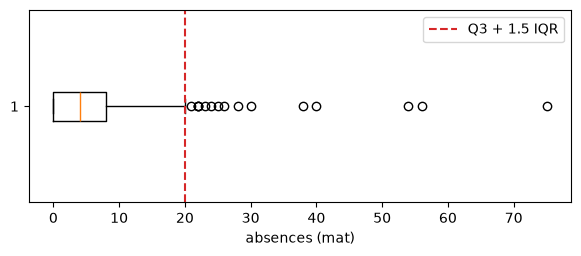

In [4]:
mat = clean[clean['subject'] == 'mat']
zero = mat[mat['dropout_suspect']]
print('G3 = 0 students:', len(zero), '| with absences == 0:', int((zero['absences'] == 0).sum()),
      '| with G2 == 0:', int((zero['G2'] == 0).sum()))
print(zero[['G1', 'G2', 'G3', 'absences', 'failures']].describe().loc[['mean', 'min', 'max']])

import matplotlib.pyplot as plt
fig, ax = plt.subplots(figsize=(7, 2.5))
ax.boxplot(mat['absences'], orientation='horizontal')
ax.axvline(log['absence_outlier_fence']['mat'], color='C3', ls='--', label='Q3 + 1.5 IQR')
ax.set_xlabel('absences (mat)'); ax.legend(); plt.show()

## 4. EDA: groupby mean/std (all vs exclude_dropout)

In [5]:
res = proc.analyze()
for scope in ['all', 'exclude_dropout']:
    s = res['scopes'][scope]
    print(f"\n### {scope}: n={s['n']} pass_rate={s['pass_rate']} (pass {s['n_pass']} / fail {s['n_fail']})")
    for key in ['by_studytime', 'by_absence_level', 'by_failures', 'by_internet',
                'by_famsup', 'by_schoolsup', 'by_paid', 'by_risk_group']:
        print(f"  {key}: " + ', '.join(f"{g}={v['mean']}±{v['std']} (n={v['n']})" for g, v in s[key].items()))


### all: n=395 pass_rate=0.6709 (pass 265 / fail 130)
  by_studytime: 1=10.05±4.96 (n=105), 2=10.17±4.22 (n=198), 3=11.4±4.64 (n=65), 4=11.26±5.28 (n=27)
  by_absence_level: high=10.37±3.2 (n=83), low=9.82±5.61 (n=191), medium=11.38±3.25 (n=121)
  by_failures: 0=11.25±4.17 (n=312), 1=8.12±4.71 (n=50), 2=6.24±4.84 (n=17), 3=5.69±4.19 (n=16)
  by_internet: no=9.41±4.49 (n=66), yes=10.62±4.58 (n=329)
  by_famsup: no=10.64±4.64 (n=153), yes=10.27±4.55 (n=242)
  by_schoolsup: no=10.56±4.77 (n=344), yes=9.43±2.87 (n=51)
  by_paid: no=9.99±5.13 (n=214), yes=10.92±3.79 (n=181)
  by_risk_group: high=6.22±3.85 (n=149), low=13.57±2.51 (n=169), medium=11.6±2.83 (n=77)

### exclude_dropout: n=357 pass_rate=0.7423 (pass 265 / fail 92)
  by_studytime: 1=11.47±3.41 (n=92), 2=11.07±3.07 (n=182), 3=12.56±2.99 (n=59), 4=12.67±3.6 (n=24)
  by_absence_level: high=10.37±3.2 (n=83), low=12.26±3.04 (n=153), medium=11.38±3.25 (n=121)
  by_failures: 0=11.94±3.19 (n=294), 1=10.15±2.6 (n=40), 2=8.83±3.01 (n=12),

## 5. Charts (3 required)

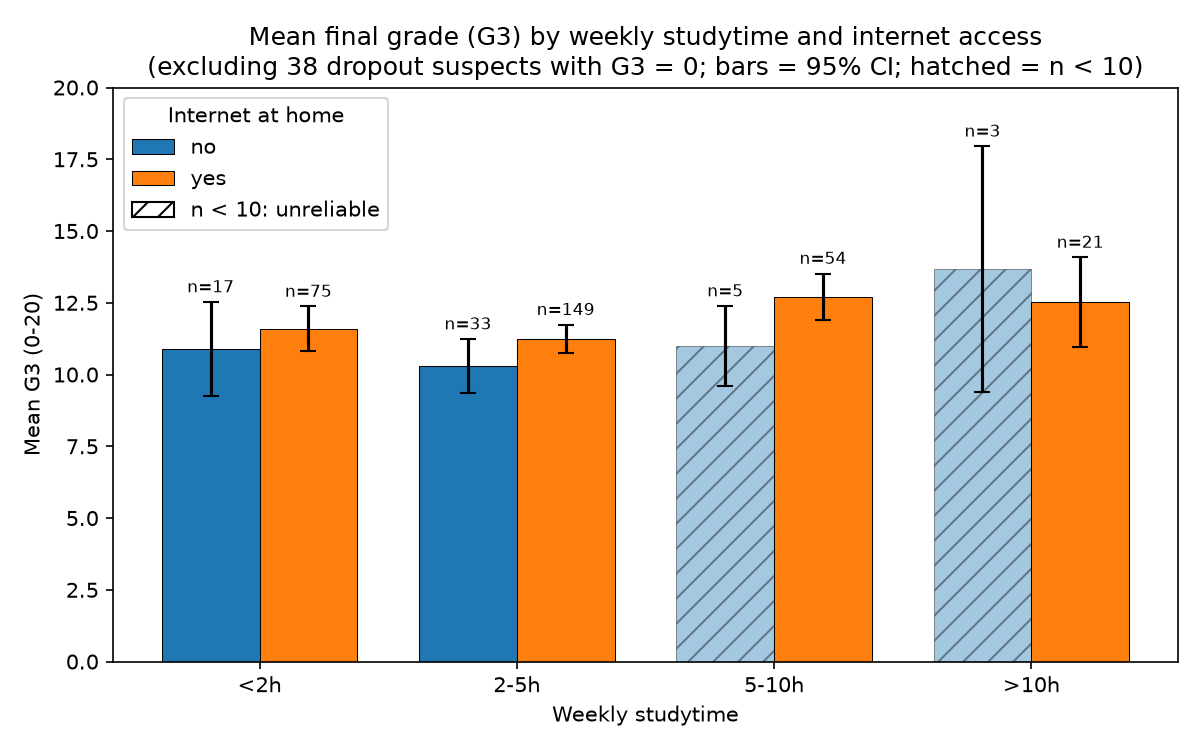

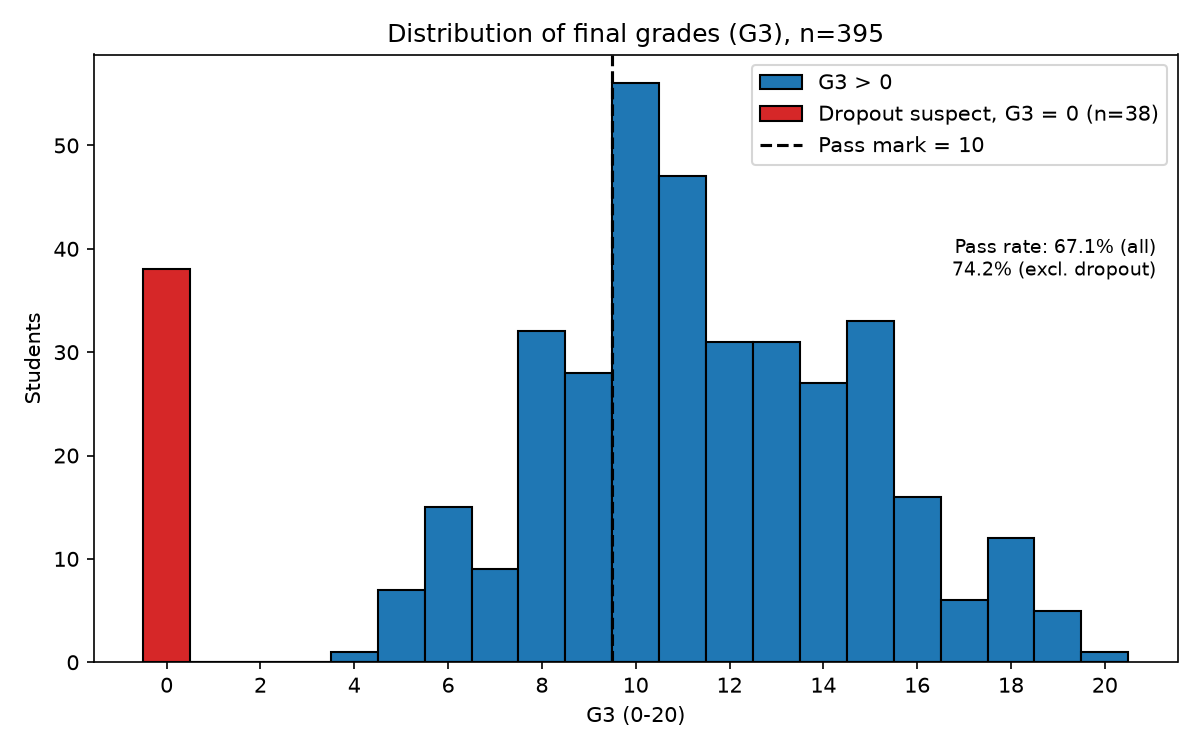

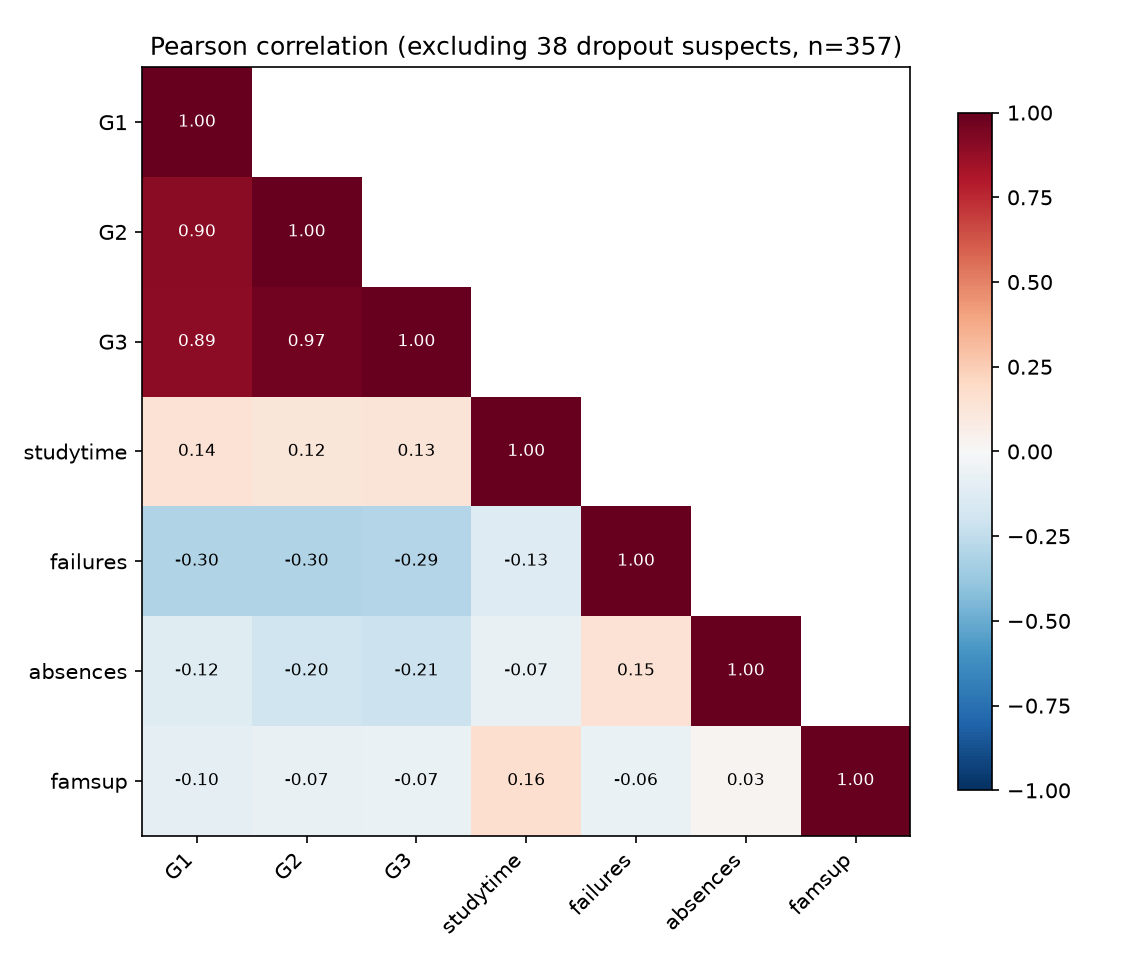

In [6]:
from IPython.display import Image, display
for name in ['01_bar_studytime_internet.png', '02_hist_g3.png', '03_heatmap_corr.png']:
    display(Image(f'images/{name}'))

## 6. Correlation G1/G2/G3 (effect of dropout suspects)

In [7]:
import pandas as pd
for scope in ['all', 'exclude_dropout']:
    print(scope, res['scopes'][scope]['corr_G1_G2_G3'])
print(pd.DataFrame(res['scopes']['exclude_dropout']['corr_full']).round(2).to_string())

all {'G1_G2': 0.852, 'G1_G3': 0.801, 'G2_G3': 0.905}
exclude_dropout {'G1_G2': 0.902, 'G1_G3': 0.892, 'G2_G3': 0.966}
              G1    G2    G3  studytime  failures  absences  famsup_bin
G1          1.00  0.90  0.89       0.14     -0.30     -0.12       -0.10
G2          0.90  1.00  0.97       0.12     -0.30     -0.20       -0.07
G3          0.89  0.97  1.00       0.13     -0.29     -0.21       -0.07
studytime   0.14  0.12  0.13       1.00     -0.13     -0.08        0.16
failures   -0.30 -0.30 -0.29      -0.13      1.00      0.15       -0.06
absences   -0.12 -0.20 -0.21      -0.08      0.15      1.00        0.02
famsup_bin -0.10 -0.07 -0.07       0.16     -0.06      0.02        1.00


## 6b. Significance tests (Welch t-test / one-way ANOVA, Holm-corrected) + Pearson correlation tests

In [8]:
tests = pd.DataFrame(res['scopes']['exclude_dropout']['group_tests']).T
print(tests[['test', 'stat', 'p', 'p_holm', 'diff', 'ci95', 'eta2', 'significant']].to_string())
print()
print(pd.DataFrame(res['scopes']['exclude_dropout']['corr_tests']).T.to_string())

                        test   stat         p    p_holm  diff            ci95   eta2 significant
internet        Welch t-test   2.25    0.0268    0.0804  0.98    [0.11, 1.84]    NaN       False
famsup          Welch t-test  -1.28     0.202     0.404 -0.45   [-1.13, 0.24]    NaN       False
schoolsup       Welch t-test  -5.46  0.000001  0.000003 -2.21  [-3.02, -1.41]    NaN        True
paid            Welch t-test  -0.55     0.585     0.585 -0.19   [-0.86, 0.48]    NaN       False
studytime      one-way ANOVA   4.38   0.00482    0.0193   NaN             NaN  0.036        True
absence_level  one-way ANOVA   9.85  0.000069  0.000343   NaN             NaN  0.053        True
failures       one-way ANOVA  17.19       0.0  0.000001   NaN             NaN  0.089        True

                r         p              ci95
G1          0.892       0.0    [0.868, 0.911]
G2          0.966       0.0    [0.958, 0.972]
studytime   0.127    0.0166    [0.023, 0.228]
failures   -0.294       0.0  [-0.386, -

## 7. Risk rule evaluation (no G3 in the rule): in-sample vs holdout (Portuguese)

In [9]:
rows = []
for scope, r in res['risk_eval'].items():
    h = r['high']
    rows.append({'scope': scope, 'n': r['n'], 'fail_rate': r['fail_rate'],
                 'recall': h['recall'], 'precision': h['precision'],
                 **{f'fail_rate_{g}': v for g, v in r['fail_rate_by_group'].items()}})
print(pd.DataFrame(rows).to_string(index=False))

           scope   n  fail_rate  recall  precision  fail_rate_low  fail_rate_medium  fail_rate_high
             all 395     0.3291  0.9385     0.8188         0.0118            0.0779          0.8188
 exclude_dropout 357     0.2577  0.9348     0.7611         0.0118            0.0533          0.7611
     holdout_por 649     0.1541  0.9000     0.5921         0.0051            0.0792          0.5921
holdout_por_only 275     0.2545  0.9143     0.6598         0.0079            0.0980          0.6598


## 8. PISA reference (web scraping, country-level context) + cross-check with OECD

In [10]:
pisa = proc.pisa_clean
print(pisa.shape, pisa.groupby(['source', 'subject'])['year'].unique().to_dict())
ctx = pd.DataFrame({(subj, int(y)): v for subj, years in res['pisa_context'].items()
                    for y, v in years.items()}).T
print(ctx.to_string())
check = res['pisa_oecd_check']
for year in [k for k in check if k.isdigit()]:
    c = check[year]
    print(f"Wikipedia vs OECD {year}: {c['n_within_tolerance']}/{c['n_compared']} within ±{c['tolerance']}, mismatches: {c['mismatches']}")
print('missing in Wikipedia:', check['missing_in_wikipedia'])

(1662, 6) {('comparison', 'mathematics'): array([2000, 2003, 2006, 2009, 2012, 2015, 2018, 2022]), ('comparison', 'reading'): array([2000, 2003, 2006, 2009, 2012, 2015, 2018, 2022]), ('comparison', 'science'): array([2006, 2009, 2012, 2015, 2018, 2022]), ('summary', 'mathematics'): array([2025]), ('summary', 'reading'): array([2025]), ('summary', 'science'): array([2025])}
                  portugal  portugal_rank  oecd_average
mathematics 2000       454             23           492
            2003       466             30           499
            2006       466             35           494
            2009       487             31           495
            2012       487             29           494
            2015       492             29           490
            2018       492             28           489
            2022       472             29           472
            2025       460             30           463
reading     2000       470             26           493
        

In [11]:
cleaned_csv, summary_json = proc.export_results()
print(cleaned_csv, summary_json)

data\processed\cleaned_students.csv data\processed\summary.json


## 9. Insights + limitations

**Insights** (student-mat, 357 students after excluding the 38 dropout suspects):
- **Cleaning:** the raw UCI files are already clean (0 out-of-range values, 0 invalid yes/no, 0 duplicates). The real data problem is semantic: 38 students have G3 = 0, all with 0 recorded absences and mean G1 7.5, i.e. they most likely did not sit the final exam. They are flagged (`dropout_suspect`), not deleted; keeping them unflagged turns r(absences, G3) from −0.213 into +0.034.
- **Intermediate grades dominate:** r(G2, G3) = 0.966, r(G1, G3) = 0.892.
- **Past failures and absences pull the final grade down:** failures r = −0.294 (ANOVA η² = 0.089), absences r = −0.213 (η² = 0.053); both significant after Holm.
- **Study time helps a little:** significant after Holm (p_holm = 0.019) but explains only 3.6% of the variance.
- **Internet and family support:** internet students score ~1 point higher, but this is not significant after Holm (p_holm = 0.080); family support shows no effect (p_holm = 0.404).
- **Risk rule** (no G3 used): the `high` group catches 93.8% of failing students in `mat` (precision 81.9%). On Portuguese students never seen in `mat` (strict holdout, n = 275) recall is 91.4%, precision 66.0%.

**Limitations:** 2 schools in Portugal, 2005–06, cross-sectional data (association, not causation); studytime and absences are self-/school-reported buckets; the dropout label is an inference; small groups (e.g. studytime > 10h without internet, n = 3) are unreliable; PISA is country-level context only and is not linked to individual students.